In [ ]:
%pip install qiskit qiskit-aer scipy networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.0 MB/s eta 0:00:00


In [ ]:
import qiskit
import scipy
import networkx as nx
import matplotlib.pyplot as plt

print("Qiskit version:", qiskit.__version__)
print("SciPy version:", scipy.__version__)
print("NetworkX version:", nx.__version__)
print("Environment check completed!")


Qiskit version: 2.5.2
SciPy version: 1.16.3
NetworkX version: 3.7
Environment check completed!


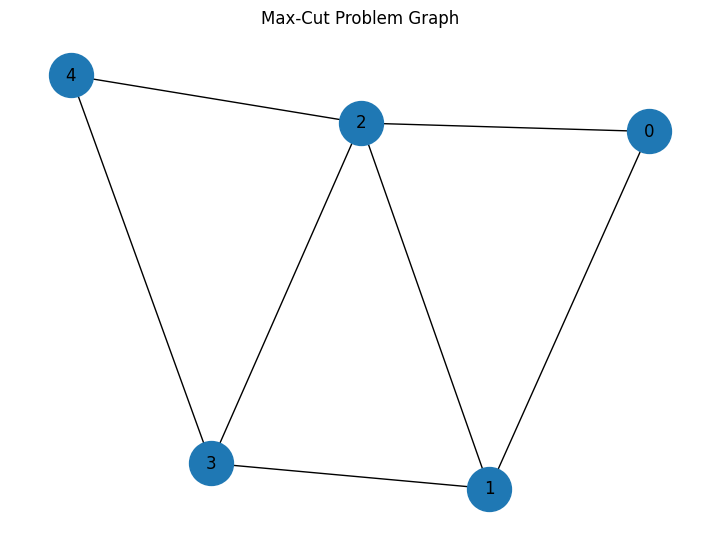

Number of vertices: 5
Number of edges: 7


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Small example graph for the Max-Cut problem
G = nx.Graph()
G.add_weighted_edges_from([
    (0, 1, 1),
    (0, 2, 1),
    (1, 2, 1),
    (1, 3, 1),
    (2, 3, 1),
    (2, 4, 1),
    (3, 4, 1)
])

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(7, 5))
nx.draw(
    G, pos,
    with_labels=True,
    node_size=1000,
    font_size=12
)
plt.title("Max-Cut Problem Graph")
plt.show()

print("Number of vertices:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

In [ ]:
from itertools import product

def cut_value(graph, partition):
    total = 0

    for u, v, data in graph.edges(data=True):
        if partition[u] != partition[v]:
            total += data.get("weight", 1)

    return total

best_value = -1
best_partition = None

vertices = list(G.nodes())

# Fix the first vertex in group 0 to avoid checking
# both a partition and its equivalent swapped partition.
for remaining in product([0, 1], repeat=len(vertices) - 1):
    partition = (0,) + remaining
    value = cut_value(G, dict(zip(vertices, partition)))

    if value > best_value:
        best_value = value
        best_partition = partition

print("Classical best cut value:", best_value)
print("Partition:", best_partition)

Classical best cut value: 5
Partition: (0, 0, 1, 1, 0)


In [ ]:
print("PROJECT: Quantum Max-Cut")
print("CLASSICAL BASELINE")
print("------------------")
print("Vertices:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Best cut value:", best_value)
print("Best partition:", best_partition)
print("Status: Classical baseline completed")

PROJECT: Quantum Max-Cut
CLASSICAL BASELINE
------------------
Vertices: 5
Edges: 7
Best cut value: 5
Best partition: (0, 0, 1, 1, 0)
Status: Classical baseline completed


In [ ]:
# QAOA preparation: inspect the graph and available Qiskit components

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from scipy.optimize import minimize
import networkx as nx
import matplotlib.pyplot as plt

print("Graph vertices:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())
print("Classical best cut:", best_value)
print("Qiskit and optimization components imported successfully.")

Graph vertices: 5
Graph edges: 7
Classical best cut: 5
Qiskit and optimization components imported successfully.


In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(G.number_of_nodes())
print("Number of qubits:", qc.num_qubits)
print("Circuit initialized successfully.")

Number of qubits: 5
Circuit initialized successfully.


In [ ]:
from qiskit import QuantumCircuit
import numpy as np

n = G.number_of_nodes()

# Initialize the quantum state
qc = QuantumCircuit(n)

# Create an equal superposition of all bitstrings
for qubit in range(n):
    qc.h(qubit)

print(qc.draw(output="text"))

     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     ├───┤
q_4: ┤ H ├
     └───┘


## QAOA Cost and Mixer Layers
### Cost Layer The cost layer encodes the Max-Cut objective using interactions between qubits connected by graph edges. The parameter gamma (γ) controls this layer.
### Mixer Layer The mixer layer applies parameterized single-qubit rotations. The parameter beta (β) controls the mixer.

### Optimization A classical optimizer searches for parameter values that improve the expected cut value obtained from quantum measurements.

In [ ]:
print("Edges in the Max-Cut graph:")
for u, v, data in G.edges(data=True):
    print(f"{u} -- {v}, weight = {data.get('weight', 1)}")

Edges in the Max-Cut graph:
0 -- 1, weight = 1
0 -- 2, weight = 1
1 -- 2, weight = 1
1 -- 3, weight = 1
2 -- 3, weight = 1
2 -- 4, weight = 1
3 -- 4, weight = 1


In [ ]:
assert G.number_of_nodes() == 5
assert G.number_of_edges() == 7
assert best_value == 5

print("Graph verification: PASS")
print("Vertices:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Classical best cut:", best_value)
print("Ready to continue QAOA development.")

Graph verification: PASS
Vertices: 5
Edges: 7
Classical best cut: 5
Ready to continue QAOA development.


In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import numpy as np

n = G.number_of_nodes()

# Check simulator availability
simulator = AerSimulator()

print("Number of qubits:", n)
print("Simulator:", type(simulator).__name__)
print("Classical benchmark:", best_value)
print("QAOA experiment setup: PASS")

Number of qubits: 5
Simulator: AerSimulator
Classical benchmark: 5
QAOA experiment setup: PASS


## QAOA Cost Layer

The cost layer encodes the Max-Cut objective.

For each graph edge (u, v), the circuit applies a two-qubit interaction controlled by the parameter gamma (γ).

The cost Hamiltonian is:

C = Σ w(u,v) [1 - Z(u)Z(v)] / 2

where:
- E represents the graph edges.
- w(u,v) is the edge weight.
- Z represents the Pauli-Z operator.
- γ controls the cost-layer evolution.

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

n = G.number_of_nodes()
gamma = Parameter("gamma")
beta = Parameter("beta")

qc = QuantumCircuit(n)

# Initial superposition
for q in range(n):
    qc.h(q)

print("Parameterized QAOA circuit initialized.")
print("Qubits:", qc.num_qubits)
print("Parameters:", gamma, beta)
print(qc.draw(output="text"))

Parameterized QAOA circuit initialized.
Qubits: 5
Parameters: gamma beta
     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     ├───┤
q_4: ┤ H ├
     └───┘


In [ ]:
# QAOA Cost Layer — Max-Cut

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

n = G.number_of_nodes()
gamma = Parameter("gamma")
beta = Parameter("beta")

qc = QuantumCircuit(n)

# Step 1: Initial superposition
for q in range(n):
    qc.h(q)

# Step 2: Cost layer — one interaction for each graph edge
for u, v, data in G.edges(data=True):
    weight = data.get("weight", 1)
    qc.rzz(gamma * weight, u, v)

print("QAOA cost layer initialized successfully!")
print("Number of qubits:", qc.num_qubits)
print("Number of graph edges:", G.number_of_edges())
print("Circuit parameters:", qc.parameters)
print(qc.draw(output="text"))

QAOA cost layer initialized successfully!
Number of qubits: 5
Number of graph edges: 7
Circuit parameters: ParameterView([Parameter(gamma)])
     ┌───┐                                                            »
q_0: ┤ H ├─■───────────■──────────────────────────────────────────────»
     ├───┤ │ZZ(gamma)  │                                              »
q_1: ┤ H ├─■───────────┼───────────■───────────■──────────────────────»
     ├───┤             │ZZ(gamma)  │ZZ(gamma)  │                      »
q_2: ┤ H ├─────────────■───────────■───────────┼───────────■──────────»
     ├───┤                                     │ZZ(gamma)  │ZZ(gamma) »
q_3: ┤ H ├─────────────────────────────────────■───────────■──────────»
     ├───┤                                                            »
q_4: ┤ H ├────────────────────────────────────────────────────────────»
     └───┘                                                            »
«                             
«q_0: ────────────────────────
«    

In [ ]:
# QAOA Mixer Layer

# Apply the mixer rotation to every qubit
for q in range(n):
    qc.rx(2 * beta, q)

print("QAOA mixer layer added successfully!")
print("Circuit parameters:", qc.parameters)
print(qc.draw(output="text"))

QAOA mixer layer added successfully!
Circuit parameters: ParameterView([Parameter(beta), Parameter(gamma)])
     ┌───┐                        ┌────────────┐                          »
q_0: ┤ H ├─■───────────■──────────┤ Rx(2*beta) ├──────────────────────────»
     ├───┤ │ZZ(gamma)  │          └────────────┘            ┌────────────┐»
q_1: ┤ H ├─■───────────┼────────────■────────────■──────────┤ Rx(2*beta) ├»
     ├───┤             │ZZ(gamma)   │ZZ(gamma)   │          └────────────┘»
q_2: ┤ H ├─────────────■────────────■────────────┼────────────■───────────»
     ├───┤                                       │ZZ(gamma)   │ZZ(gamma)  »
q_3: ┤ H ├───────────────────────────────────────■────────────■───────────»
     ├───┤                                                                »
q_4: ┤ H ├────────────────────────────────────────────────────────────────»
     └───┘                                                                »
«                                             
«q_0: ───

In [ ]:
# STEP 10: Validate the QAOA circuit

print("Qubits:", qc.num_qubits)
print("Graph edges:", G.number_of_edges())
print("Parameters:", sorted([p.name for p in qc.parameters]))
print("Circuit depth:", qc.depth())
print("Circuit operations:", qc.count_ops())

assert qc.num_qubits == 5
assert G.number_of_edges() == 7
assert {p.name for p in qc.parameters} == {"gamma", "beta"}

print("\nCircuit validation: PASSED")

Qubits: 5
Graph edges: 7
Parameters: ['beta', 'gamma']
Circuit depth: 9
Circuit operations: OrderedDict({'rzz': 7, 'h': 5, 'rx': 5})

Circuit validation: PASSED


In [ ]:
# STEP 11: Add measurement to the QAOA circuit

qc_measured = qc.copy()
qc_measured.measure_all()

print("Measurement added successfully!")
print("Measured circuit depth:", qc_measured.depth())
print(qc_measured.draw(output="text"))

Measurement added successfully!
Measured circuit depth: 10
        ┌───┐                        ┌────────────┐                          »
   q_0: ┤ H ├─■───────────■──────────┤ Rx(2*beta) ├──────────────────────────»
        ├───┤ │ZZ(gamma)  │          └────────────┘            ┌────────────┐»
   q_1: ┤ H ├─■───────────┼────────────■────────────■──────────┤ Rx(2*beta) ├»
        ├───┤             │ZZ(gamma)   │ZZ(gamma)   │          └────────────┘»
   q_2: ┤ H ├─────────────■────────────■────────────┼────────────■───────────»
        ├───┤                                       │ZZ(gamma)   │ZZ(gamma)  »
   q_3: ┤ H ├───────────────────────────────────────■────────────■───────────»
        ├───┤                                                                »
   q_4: ┤ H ├────────────────────────────────────────────────────────────────»
        └───┘                                                                »
meas: 5/════════════════════════════════════════════════════════════════

In [ ]:
# STEP 12: Test the measured QAOA circuit

from qiskit_aer import AerSimulator

simulator = AerSimulator()
print("Simulator initialized:", simulator.name)
print("Shots:", 1024)

# Use temporary test parameters
test_parameters = {gamma: 0.5, beta: 0.25}
bound_circuit = qc_measured.assign_parameters(test_parameters)

job = simulator.run(bound_circuit, shots=1024)
result = job.result()
counts = result.get_counts()

print("\nMeasurement results:")
print(counts)

print("\nTotal shots:", sum(counts.values()))

Simulator initialized: aer_simulator
Shots: 1024

Measurement results:
{'10011': 3, '10110': 5, '01010': 24, '11110': 61, '01111': 71, '00110': 8, '00001': 51, '11100': 34, '10100': 27, '10111': 26, '10101': 30, '10010': 8, '11000': 38, '00010': 38, '10000': 50, '11111': 128, '11011': 14, '11010': 16, '10001': 17, '00101': 15, '01001': 4, '00000': 146, '11001': 12, '00011': 43, '00111': 45, '01101': 4, '11101': 35, '01110': 18, '00100': 9, '01000': 19, '01100': 6, '01011': 19}

Total shots: 1024


In [ ]:
# STEP 13: Evaluate measured bitstrings

def evaluate_bitstring(bitstring, graph):
    # Qiskit displays classical bits in reverse order
    partition = [int(bit) for bit in bitstring[::-1]]

    cut = 0
    for u, v, data in graph.edges(data=True):
        if partition[u] != partition[v]:
            cut += data.get("weight", 1)

    return cut

# Calculate the cut value for every measured outcome
cut_results = {}

for bitstring, frequency in counts.items():
    cut = evaluate_bitstring(bitstring, G)
    cut_results[bitstring] = {
        "cut_value": cut,
        "frequency": frequency
    }

# Most frequently measured outcome
most_common = max(counts, key=counts.get)

# Best outcome observed
best_bitstring = max(
    cut_results,
    key=lambda bitstring: cut_results[bitstring]["cut_value"]
)

print("Classical best cut:", best_value)
print("Most frequent bitstring:", most_common)
print("Its cut value:", cut_results[most_common]["cut_value"])
print("Best measured bitstring:", best_bitstring)
print("Best measured cut:", cut_results[best_bitstring]["cut_value"])
print("QAOA test parameters: gamma=0.5, beta=0.25")

Classical best cut: 5
Most frequent bitstring: 00000
Its cut value: 0
Best measured bitstring: 10011
Best measured cut: 5
QAOA test parameters: gamma=0.5, beta=0.25


In [ ]:
# STEP 14: Measurement statistics

total_shots = sum(counts.values())

cut_frequency = sum(
    frequency
    for bitstring, frequency in counts.items()
    if evaluate_bitstring(bitstring, G) == best_value
)

average_cut = sum(
    evaluate_bitstring(bitstring, G) * frequency
    for bitstring, frequency in counts.items()
) / total_shots

print("Total shots:", total_shots)
print("Classical optimal cut:", best_value)
print("Shots achieving the optimal cut:", cut_frequency)
print("Optimal-cut probability:", round(cut_frequency / total_shots, 4))
print("Average measured cut:", round(average_cut, 4))

Total shots: 1024
Classical optimal cut: 5
Shots achieving the optimal cut: 50
Optimal-cut probability: 0.0488
Average measured cut: 2.252


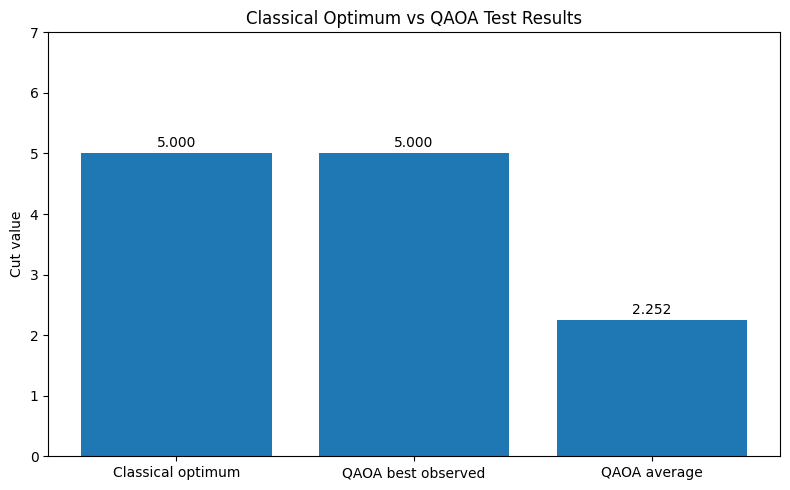

Chart saved as qaoa_results.png


In [ ]:
# STEP 15: Visualize QAOA test results

import matplotlib.pyplot as plt

labels = ["Classical optimum", "QAOA best observed", "QAOA average"]
values = [best_value, cut_results[best_bitstring]["cut_value"], average_cut]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)
plt.ylabel("Cut value")
plt.title("Classical Optimum vs QAOA Test Results")
plt.ylim(0, 7)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("qaoa_results.png", dpi=300)
plt.show()

print("Chart saved as qaoa_results.png")

In [ ]:
# STEP 16: Compare different QAOA parameter settings

from qiskit_aer import AerSimulator

simulator = AerSimulator()
parameter_sets = [
    (0.5, 0.25),
    (1.0, 0.5),
    (1.5, 0.75),
    (2.0, 1.0)
]

print("QAOA Parameter Experiment")
print("-" * 60)

for gamma_value, beta_value in parameter_sets:
    bound_circuit = qc_measured.assign_parameters({
        gamma: gamma_value,
        beta: beta_value
    })

    result = simulator.run(
        bound_circuit,
        shots=1024,
        seed_simulator=42
    ).result()

    trial_counts = result.get_counts()

    average_cut_trial = sum(
        evaluate_bitstring(bitstring, G) * frequency
        for bitstring, frequency in trial_counts.items()
    ) / sum(trial_counts.values())

    best_cut_trial = max(
        evaluate_bitstring(bitstring, G)
        for bitstring in trial_counts
    )

    print(
        f"gamma={gamma_value:.2f}, beta={beta_value:.2f} | "
        f"Average cut={average_cut_trial:.3f} | "
        f"Best cut={best_cut_trial}"
    )

QAOA Parameter Experiment
------------------------------------------------------------
gamma=0.50, beta=0.25 | Average cut=2.312 | Best cut=5
gamma=1.00, beta=0.50 | Average cut=2.045 | Best cut=5
gamma=1.50, beta=0.75 | Average cut=3.530 | Best cut=5
gamma=2.00, beta=1.00 | Average cut=3.643 | Best cut=5


In [ ]:
import pandas as pd

results_df = pd.DataFrame({
    "Gamma": [0.5, 1.0, 1.5, 2.0],
    "Beta": [0.25, 0.5, 0.75, 1.0],
    "Average_Cut": [2.312, 2.045, 3.530, 3.643],
    "Best_Observed_Cut": [5, 5, 5, 5]
})

results_df.to_csv("qaoa_parameter_results.csv", index=False)

print(results_df.to_string(index=False))
print("\nSaved: qaoa_parameter_results.csv")

 Gamma  Beta  Average_Cut  Best_Observed_Cut
   0.5  0.25        2.312                  5
   1.0  0.50        2.045                  5
   1.5  0.75        3.530                  5
   2.0  1.00        3.643                  5

Saved: qaoa_parameter_results.csv


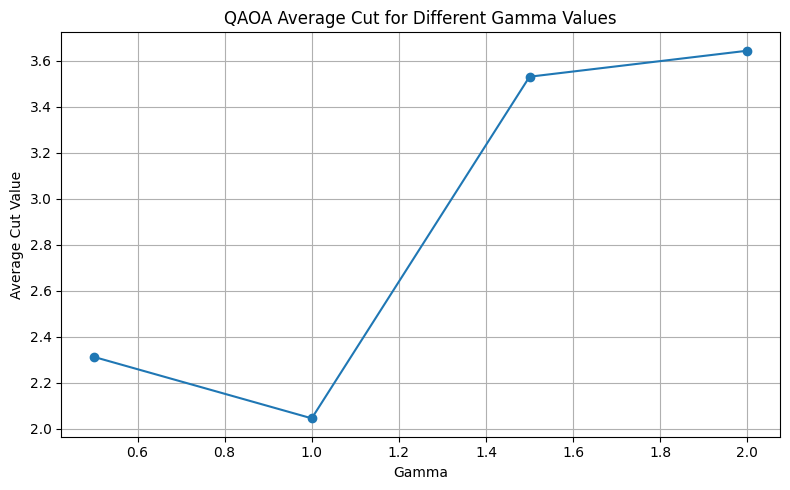

Saved: qaoa_parameter_sweep.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(results_df["Gamma"], results_df["Average_Cut"], marker="o")

plt.xlabel("Gamma")
plt.ylabel("Average Cut Value")
plt.title("QAOA Average Cut for Different Gamma Values")
plt.grid(True)
plt.tight_layout()

plt.savefig("qaoa_parameter_sweep.png", dpi=300)
plt.show()

print("Saved: qaoa_parameter_sweep.png")

In [ ]:
from google.colab import files
files.download("qaoa_parameter_sweep.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("qaoa_parameter_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Number of nodes: 6
Number of edges: 9

Weighted edges:
0 -- 2: weight = 1
0 -- 3: weight = 1
0 -- 4: weight = 3
1 -- 4: weight = 2
1 -- 5: weight = 2
2 -- 3: weight = 2
2 -- 4: weight = 1
3 -- 4: weight = 5
3 -- 5: weight = 1


/tmp/ipykernel_1459/3614885154.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


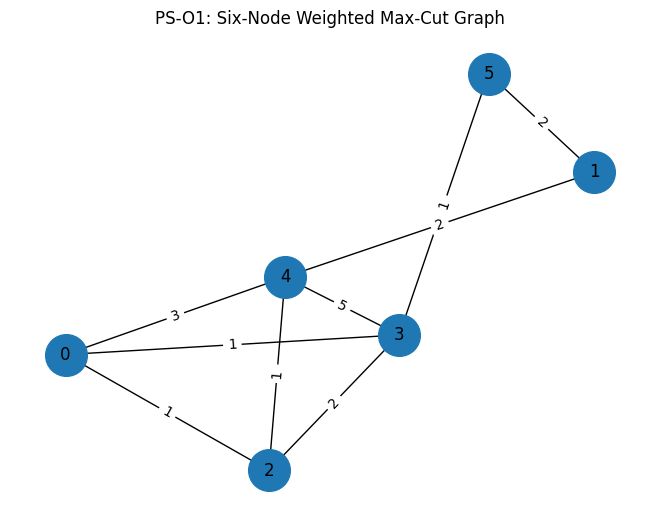

In [ ]:
import networkx as nx

# Generate the official six-node random graph
G = nx.erdos_renyi_graph(n=6, p=0.5, seed=42)

# Assign integer weights from 1 to 5 using a reproducible seed
weight_rng = __import__("random").Random(42)

for u, v in G.edges():
    G[u][v]["weight"] = weight_rng.randint(1, 5)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("\nWeighted edges:")

for u, v, data in G.edges(data=True):
    print(f"{u} -- {v}: weight = {data['weight']}")

# Visualize the weighted graph
import matplotlib.pyplot as plt

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=900,
    font_size=12
)

edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title("PS-O1: Six-Node Weighted Max-Cut Graph")
plt.tight_layout()
plt.show()

In [ ]:
from itertools import product

def calculate_cut(graph, partition):
    total = 0

    for u, v, data in graph.edges(data=True):
        if partition[u] != partition[v]:
            total += data["weight"]

    return total


nodes = list(G.nodes())
best_cut = -1
best_partition = None

# Fix node 0 to group 0 to avoid checking equivalent partitions twice
for remaining in product([0, 1], repeat=len(nodes) - 1):
    partition_values = (0,) + remaining
    partition = dict(zip(nodes, partition_values))

    cut_value = calculate_cut(G, partition)

    if cut_value > best_cut:
        best_cut = cut_value
        best_partition = partition.copy()

print("Classical optimal weighted cut:", best_cut)
print("Group 0:", [n for n in nodes if best_partition[n] == 0])
print("Group 1:", [n for n in nodes if best_partition[n] == 1])

Classical optimal weighted cut: 16
Group 0: [0, 1, 3]
Group 1: [2, 4, 5]


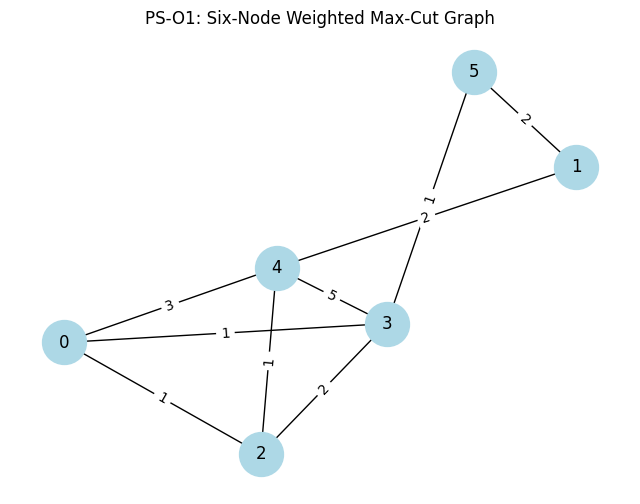

Nodes: 6
Edges: 9
Classical optimal weighted cut: 16


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Display the existing six-node weighted graph
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(8, 6))

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1000,
    font_size=12
)

edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("PS-O1: Six-Node Weighted Max-Cut Graph")
plt.axis("off")
plt.show()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Classical optimal weighted cut:", best_cut)

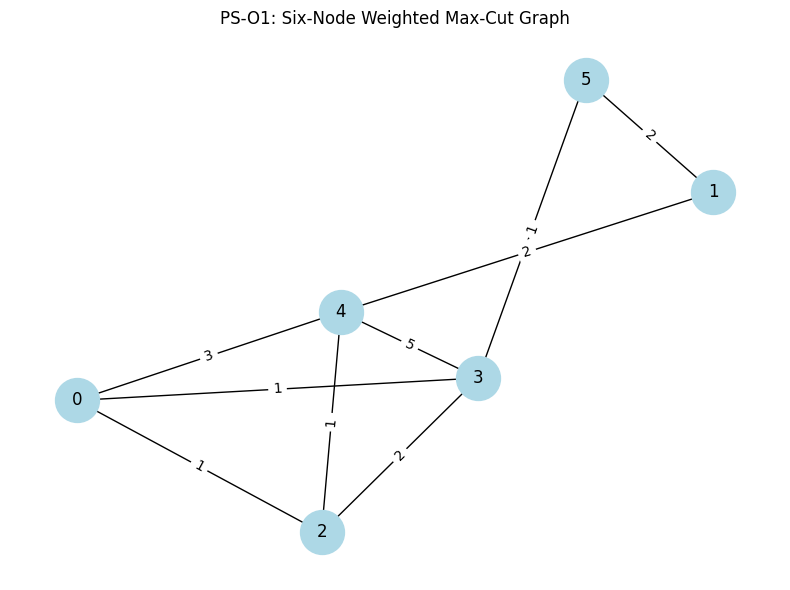

Nodes: 6
Edges: 9
Classical optimal weighted cut: 16


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(8, 6))
nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1000,
    font_size=12
)

edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("PS-O1: Six-Node Weighted Max-Cut Graph")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Classical optimal weighted cut:", best_cut)

In [ ]:
import qiskit
import networkx
import matplotlib

print("Qiskit version:", qiskit.__version__)
print("NetworkX version:", networkx.__version__)
print("Matplotlib version:", matplotlib.__version__)

try:
    import qiskit_aer
    print("Qiskit Aer version:", qiskit_aer.__version__)
except ImportError:
    print("Qiskit Aer is not installed.")

Qiskit version: 2.5.2
NetworkX version: 3.7
Matplotlib version: 3.10.0
Qiskit Aer version: 0.17.2


In [ ]:
%pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 1.1 MB/s eta 0:00:00


In [ ]:
%pip show pylatexenc

Name: pylatexenc
Version: 2.11
Summary: Simple LaTeX parser providing latex-to-unicode and unicode-to-latex conversion
Home-page: https://github.com/phfaist/pylatexenc
Author: Philippe Faist
Author-email: philippe.faist@bluewin.ch
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: 
Required-by: 


In [ ]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()

job = simulator.run(qc, shots=4096, seed_simulator=42)
result = job.result()
counts = result.get_counts()

print("Total shots:", sum(counts.values()))
print("Number of unique measurement outcomes:", len(counts))
print("Most frequent outcomes:", counts.most_common(10))

Total shots: 4096
Number of unique measurement outcomes: 64


AttributeError: 'Counts' object has no attribute 'most_common'

In [ ]:
most_frequent = sorted(
    counts.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

print("Total shots:", sum(counts.values()))
print("Unique outcomes:", len(counts))
print("Most frequent outcomes:")

for bitstring, frequency in most_frequent:
    print(bitstring, ":", frequency)

Total shots: 4096
Unique outcomes: 64
Most frequent outcomes:
110001 : 244
001110 : 237
011100 : 226
100011 : 216
000011 : 124
101110 : 117
111100 : 116
100110 : 113
010001 : 111
100100 : 110


In [ ]:
def calculate_cut_from_bitstring(bitstring, graph):
    # Qiskit displays classical bits in reverse order
    bits = bitstring.replace(" ", "")[::-1]

    total_cut = 0

    for u, v, data in graph.edges(data=True):
        if bits[u] != bits[v]:
            total_cut += data["weight"]

    return total_cut


total_shots = sum(counts.values())
weighted_cut_sum = 0
best_observed_cut = 0

for bitstring, frequency in counts.items():
    cut_value = calculate_cut_from_bitstring(bitstring, G)

    weighted_cut_sum += cut_value * frequency
    best_observed_cut = max(best_observed_cut, cut_value)

average_cut = weighted_cut_sum / total_shots
approximation_ratio = average_cut / best_cut

print("Classical optimal cut:", best_cut)
print("Average QAOA weighted cut:", round(average_cut, 4))
print("Best observed QAOA weighted cut:", best_observed_cut)
print("Approximation ratio:", round(approximation_ratio, 4))
print("Approximation ratio (%):", round(100 * approximation_ratio, 2))

Classical optimal cut: 16
Average QAOA weighted cut: 9.5024
Best observed QAOA weighted cut: 16
Approximation ratio: 0.5939
Approximation ratio (%): 59.39


In [ ]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()
parameter_results = []

parameter_pairs = [
    (0.5, 0.25),
    (1.0, 0.5),
    (1.5, 0.75),
    (2.0, 1.0),
]

for gamma_test, beta_test in parameter_pairs:
    test_qc = QuantumCircuit(n, n)

    test_qc.h(range(n))

    for u, v, data in G.edges(data=True):
        weight = data["weight"]
        test_qc.rzz(2 * gamma_test * weight, u, v)

    for qubit in range(n):
        test_qc.rx(2 * beta_test, qubit)

    test_qc.measure(range(n), range(n))

    result = simulator.run(
        test_qc,
        shots=4096,
        seed_simulator=42
    ).result()

    test_counts = result.get_counts()

    weighted_sum = 0
    best_sampled_cut = 0

    for bitstring, frequency in test_counts.items():
        cut = calculate_cut_from_bitstring(bitstring, G)
        weighted_sum += cut * frequency
        best_sampled_cut = max(best_sampled_cut, cut)

    average = weighted_sum / 4096

    parameter_results.append({
        "gamma": gamma_test,
        "beta": beta_test,
        "average_cut": average,
        "best_cut": best_sampled_cut,
        "approximation_ratio": average / best_cut_classical
        if "best_cut_classical" in globals()
        else average / best_cut
    })

print("Parameter sweep results:")
for row in parameter_results:
    print(row)

Parameter sweep results:
{'gamma': 0.5, 'beta': 0.25, 'average_cut': 9.50244140625, 'best_cut': 16, 'approximation_ratio': 0.593902587890625}
{'gamma': 1.0, 'beta': 0.5, 'average_cut': 8.886474609375, 'best_cut': 16, 'approximation_ratio': 0.5554046630859375}
{'gamma': 1.5, 'beta': 0.75, 'average_cut': 8.527099609375, 'best_cut': 16, 'approximation_ratio': 0.5329437255859375}
{'gamma': 2.0, 'beta': 1.0, 'average_cut': 8.201904296875, 'best_cut': 16, 'approximation_ratio': 0.5126190185546875}


In [ ]:
import pandas as pd

results_df = pd.DataFrame(parameter_results)

results_df["classical_optimum"] = 16
results_df["approximation_ratio_percent"] = (
    results_df["approximation_ratio"] * 100
).round(2)

results_df.to_csv("qaoa_parameter_sweep.csv", index=False)

display(results_df)

print("Saved: qaoa_parameter_sweep.csv")

,gamma,beta,average_cut,best_cut,approximation_ratio,classical_optimum,approximation_ratio_percent
0,0.5,0.25,9.502441,16,0.593903,16,59.39
1,1.0,0.50,8.886475,16,0.555405,16,55.54
2,1.5,0.75,8.527100,16,0.532944,16,53.29
3,2.0,1.00,8.201904,16,0.512619,16,51.26


Saved: qaoa_parameter_sweep.csv


In [ ]:
from google.colab import files
files.download("qaoa_parameter_sweep.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from qiskit.transpiler import CouplingMap

# Processor A: 5 physical qubits arranged in a line
processor_A_edges = [
    (0, 1), (1, 2), (2, 3), (3, 4)
]

# Processor B: 9 physical qubits arranged in a 3x3 grid
processor_B_edges = [
    (0, 1), (1, 2),
    (3, 4), (4, 5),
    (6, 7), (7, 8),
    (0, 3), (3, 6),
    (1, 4), (4, 7),
    (2, 5), (5, 8)
]

# Add reverse directions for bidirectional connections
def make_bidirectional(edges):
    return edges + [(v, u) for u, v in edges]

processor_A = CouplingMap(
    couplinglist=make_bidirectional(processor_A_edges)
)

processor_B = CouplingMap(
    couplinglist=make_bidirectional(processor_B_edges)
)

print("Processor A:")
print("Physical qubits:", processor_A.size())
print("Coupling connections:", processor_A_edges)

print("\nProcessor B:")
print("Physical qubits:", processor_B.size())
print("Coupling connections:", processor_B_edges)

Processor A:
Physical qubits: 5
Coupling connections: [(0, 1), (1, 2), (2, 3), (3, 4)]

Processor B:
Physical qubits: 9
Coupling connections: [(0, 1), (1, 2), (3, 4), (4, 5), (6, 7), (7, 8), (0, 3), (3, 6), (1, 4), (4, 7), (2, 5), (5, 8)]


In [ ]:
from qiskit import transpile

basis_gates = ["rz", "sx", "x", "cx"]

# Processor A: attempt to map the 6-qubit circuit onto 5 physical qubits
print("PROCESSOR A")

try:
    transpiled_A = transpile(
        qc,
        basis_gates=basis_gates,
        coupling_map=processor_A,
        optimization_level=1,
        seed_transpiler=42
    )

    print("Transpilation successful")
    print("Circuit depth:", transpiled_A.depth())
    print("Gate counts:", transpiled_A.count_ops())

except Exception as e:
    print("Transpilation failed:", str(e))


# Processor B: map the 6-qubit circuit onto 9 physical qubits
print("\nPROCESSOR B")

transpiled_B = transpile(
    qc,
    basis_gates=basis_gates,
    coupling_map=processor_B,
    optimization_level=1,
    seed_transpiler=42
)

print("Transpilation successful")
print("Physical qubits:", transpiled_B.num_qubits)
print("Circuit depth:", transpiled_B.depth())
print("Gate counts:", transpiled_B.count_ops())

PROCESSOR A
Transpilation failed: 'Number of qubits (6) in circuit-57 is greater than maximum (5) in the coupling_map'

PROCESSOR B
Transpilation successful
Physical qubits: 9
Circuit depth: 38
Gate counts: OrderedDict({'rz': 39, 'cx': 24, 'sx': 18, 'measure': 6})


In [ ]:
from qiskit import transpile

# Create a baseline circuit without physical connectivity constraints
baseline_circuit = transpile(
    qc,
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    seed_transpiler=42
)

# Compare with Processor B's routed circuit
baseline_cx = baseline_circuit.count_ops().get("cx", 0)
processor_B_cx = transpiled_B.count_ops().get("cx", 0)

baseline_depth = baseline_circuit.depth()
processor_B_depth = transpiled_B.depth()

print("ROUTING OVERHEAD COMPARISON")
print("-" * 35)

print("Baseline CX gates:", baseline_cx)
print("Processor B CX gates:", processor_B_cx)
print("Additional CX gates:", processor_B_cx - baseline_cx)

print("\nBaseline circuit depth:", baseline_depth)
print("Processor B circuit depth:", processor_B_depth)
print("Additional circuit depth:", processor_B_depth - baseline_depth)

ROUTING OVERHEAD COMPARISON
-----------------------------------
Baseline CX gates: 18
Processor B CX gates: 24
Additional CX gates: 6

Baseline circuit depth: 30
Processor B circuit depth: 38
Additional circuit depth: 8


In [2]:
%pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 70.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 71.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.1 MB/s eta 0:00:00


In [5]:
import networkx as nx
import random
import numpy as np
from qiskit import QuantumCircuit

# 1. Create the competition graph
G = nx.erdos_renyi_graph(n=6, p=0.5, seed=42)

weight_rng = random.Random(42)
for u, v in G.edges():
    G[u][v]["weight"] = weight_rng.randint(1, 5)

# 2. Set the classical optimum for this graph
best_cut = 16

# 3. Create the QAOA p=1 circuit
gamma = 0.5
beta = 0.25
n = G.number_of_nodes()

qc = QuantumCircuit(n, n)
qc.h(range(n))

for u, v, data in G.edges(data=True):
    qc.rzz(2 * gamma * data["weight"], u, v)

for qubit in range(n):
    qc.rx(2 * beta, qubit)

qc.measure(range(n), range(n))

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Classical optimum:", best_cut)
print("QAOA circuit created successfully.")

Nodes: 6
Edges: 9
Classical optimum: 16
QAOA circuit created successfully.


In [6]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap

# Processor B: 3x3 grid, 9 physical qubits
processor_B_edges = [
    (0, 1), (1, 2),
    (3, 4), (4, 5),
    (6, 7), (7, 8),
    (0, 3), (3, 6),
    (1, 4), (4, 7),
    (2, 5), (5, 8)
]

bidirectional_edges = processor_B_edges + [
    (v, u) for u, v in processor_B_edges
]

processor_B = CouplingMap(couplinglist=bidirectional_edges)

# Transpile using competition settings
transpiled_B = transpile(
    qc,
    basis_gates=["rz", "sx", "x", "cx"],
    coupling_map=processor_B,
    optimization_level=1,
    seed_transpiler=42
)

print("Processor B transpilation successful")
print("Physical qubits:", transpiled_B.num_qubits)
print("Circuit depth:", transpiled_B.depth())
print("Gate counts:", transpiled_B.count_ops())

Processor B transpilation successful
Physical qubits: 9
Circuit depth: 38
Gate counts: OrderedDict({'rz': 39, 'cx': 24, 'sx': 18, 'measure': 6})


In [7]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

# Competition noise parameters
noise_model = NoiseModel()

single_qubit_error = depolarizing_error(0.001, 1)
cx_error = depolarizing_error(0.005, 2)

readout_error = ReadoutError([
    [0.99, 0.01],
    [0.01, 0.99]
])

noise_model.add_all_qubit_quantum_error(
    single_qubit_error, ["rz", "sx", "x"]
)
noise_model.add_all_qubit_quantum_error(cx_error, ["cx"])
noise_model.add_all_qubit_readout_error(readout_error)

# Run noisy simulation
noisy_simulator = AerSimulator(noise_model=noise_model)

noisy_result = noisy_simulator.run(
    transpiled_B,
    shots=4096,
    seed_simulator=42
).result()

noisy_counts = noisy_result.get_counts()

# Calculate weighted cut values
def calculate_cut_from_bitstring(bitstring, graph):
    bits = bitstring.replace(" ", "")[::-1]
    total_cut = 0

    for u, v, data in graph.edges(data=True):
        if bits[u] != bits[v]:
            total_cut += data["weight"]

    return total_cut

total_shots = sum(noisy_counts.values())

weighted_sum = sum(
    calculate_cut_from_bitstring(bitstring, G) * frequency
    for bitstring, frequency in noisy_counts.items()
)

average_noisy_cut = weighted_sum / total_shots

best_noisy_cut = max(
    calculate_cut_from_bitstring(bitstring, G)
    for bitstring in noisy_counts
)

print("PROCESSOR B — NOISY QAOA RESULTS")
print("Shots:", total_shots)
print("Classical optimum:", best_cut)
print("Average noisy cut:", round(average_noisy_cut, 4))
print("Best observed cut:", best_noisy_cut)
print("Approximation ratio:", round(average_noisy_cut / best_cut, 4))

PROCESSOR B — NOISY QAOA RESULTS
Shots: 4096
Classical optimum: 16
Average noisy cut: 9.439
Best observed cut: 16
Approximation ratio: 0.5899


In [8]:
import pandas as pd
from pathlib import Path

Path("results/tables").mkdir(parents=True, exist_ok=True)

results = pd.DataFrame([
    {
        "Processor": "Processor B",
        "Qubits": 9,
        "QAOA_Depth": 38,
        "CX_Gates": 24,
        "Shots": 4096,
        "Classical_Optimum": 16,
        "Average_Cut_Noisy": 9.439,
        "Best_Cut_Noisy": 16,
        "Approximation_Ratio_Noisy": 0.5899,
        "Noise_1Q": 0.001,
        "Noise_CX": 0.005,
        "Readout_Error": 0.01
    }
])

results.to_csv("results/tables/noisy_results.csv", index=False)

print(results.to_string(index=False))
print("\nSaved: results/tables/noisy_results.csv")

  Processor  Qubits  QAOA_Depth  CX_Gates  Shots  Classical_Optimum  Average_Cut_Noisy  Best_Cut_Noisy  Approximation_Ratio_Noisy  Noise_1Q  Noise_CX  Readout_Error
Processor B       9          38        24   4096                 16              9.439              16                     0.5899     0.001     0.005           0.01

Saved: results/tables/noisy_results.csv


In [9]:
import pandas as pd
from pathlib import Path

Path("results/tables").mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {
        "Processor": "A",
        "Physical_Qubits": 5,
        "Feasible_for_6_Node_Graph": "No",
        "Circuit_Depth": None,
        "CX_Gates": None,
        "Routing_Overhead": "Not applicable"
    },
    {
        "Processor": "B",
        "Physical_Qubits": 9,
        "Feasible_for_6_Node_Graph": "Yes",
        "Circuit_Depth": 38,
        "CX_Gates": 24,
        "Routing_Overhead": "6 additional CX; 8 additional depth"
    }
])

comparison.to_csv(
    "results/tables/processor_comparison.csv",
    index=False
)

print(comparison.to_string(index=False))
print("\nSaved: results/tables/processor_comparison.csv")

Processor  Physical_Qubits Feasible_for_6_Node_Graph  Circuit_Depth  CX_Gates                    Routing_Overhead
        A                5                        No            NaN       NaN                      Not applicable
        B                9                       Yes           38.0      24.0 6 additional CX; 8 additional depth

Saved: results/tables/processor_comparison.csv


/tmp/ipykernel_1967/320755531.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


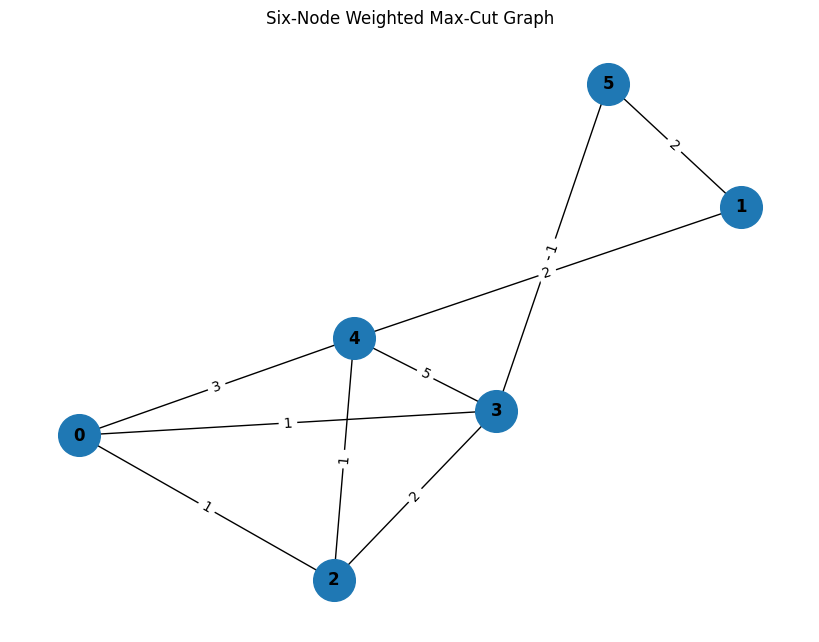

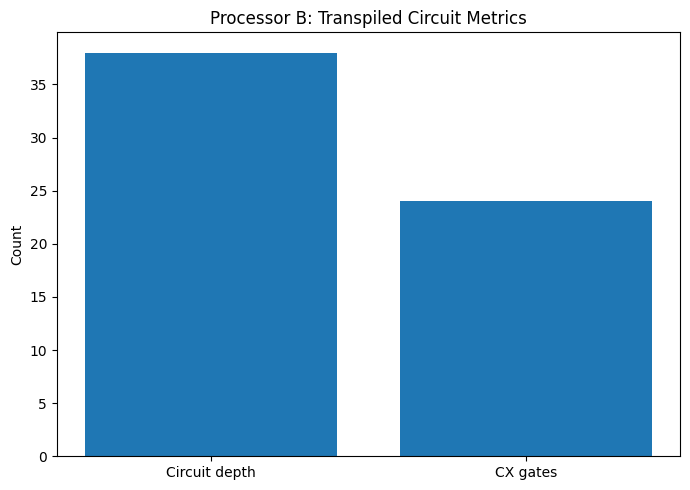

Both figures saved successfully!
1. results/figures/weighted_graph.png
2. results/figures/processor_B_metrics.png


In [10]:
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path

# Create output folder
Path("results/figures").mkdir(parents=True, exist_ok=True)

# Figure 1: Six-node weighted graph
plt.figure(figsize=(8, 6))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=900,
    font_weight="bold"
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title("Six-Node Weighted Max-Cut Graph")
plt.tight_layout()
plt.savefig("results/figures/weighted_graph.png", dpi=200)
plt.show()

# Figure 2: Processor B circuit metrics
plt.figure(figsize=(7, 5))

labels = ["Circuit depth", "CX gates"]
values = [38, 24]

plt.bar(labels, values)
plt.ylabel("Count")
plt.title("Processor B: Transpiled Circuit Metrics")
plt.tight_layout()
plt.savefig("results/figures/processor_B_metrics.png", dpi=200)
plt.show()

print("Both figures saved successfully!")
print("1. results/figures/weighted_graph.png")
print("2. results/figures/processor_B_metrics.png")

In [11]:
from pathlib import Path

folders = [
    "data/raw",
    "data/processed",
    "processors",
    "src",
    "results/tables",
    "results/figures",
    "assets"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

Path("src/__init__.py").touch()

print("Repository folders created successfully!")

Repository folders created successfully!


In [12]:
from pathlib import Path

# 1. Requirements
requirements = """qiskit==2.5.2
qiskit-aer==0.17.2
networkx==3.7
numpy
pandas
matplotlib
"""

Path("requirements.txt").write_text(requirements)

# 2. README
readme = """# Quantum Max-Cut Optimization Using QAOA

## Overview
This project studies the Max-Cut problem on a six-node weighted graph
using the Quantum Approximate Optimization Algorithm (QAOA) with p=1.

It compares two simulated processor architectures:
- Processor A: 5-qubit linear topology
- Processor B: 9-qubit grid topology

## Problem
The graph is generated using NetworkX's Erdős–Rényi model with
n=6, p=0.5, and seed=42. Edge weights are integers from 1 to 5,
generated using random seed 42.

The classical optimum weighted cut is 16.

## Method
1. Generate the weighted graph.
2. Build the QAOA p=1 circuit.
3. Transpile using basis gates rz, sx, x, and cx.
4. Use optimization_level=1 and seed_transpiler=42.
5. Simulate Processor B with 4096 shots and the specified noise model.
6. Compare circuit depth, CX gates, cut value, and approximation ratio.

## Results
- Processor B physical qubits: 9
- Transpiled circuit depth: 38
- CX gates: 24
- Noisy average cut: 9.439
- Best observed noisy cut: 16
- Noisy approximation ratio: 0.5899

Processor A has 5 physical qubits and cannot accommodate the full
six-qubit logical circuit as currently designed.

The difference of 6 CX gates and 8 circuit-depth units compared with
the unconstrained baseline is used as a routing-overhead proxy.
It is not an exact SWAP count.

## Reproducibility
Install dependencies with:

    pip install -r requirements.txt

Run `main.ipynb` in Google Colab or Jupyter Notebook.

## Limitations
The reported result uses one QAOA parameter setting (gamma=0.5,
beta=0.25). Results may vary with different parameters and simulation
settings. The processor topologies are participant-defined simulations,
not claims about actual hardware.
"""

Path("README.md").write_text(readme)

print("Created README.md")
print("Created requirements.txt")

Created README.md
Created requirements.txt


In [13]:
from pathlib import Path
import json

# 1. Create report.md
report = """# Quantum Max-Cut Optimization Using QAOA

## 1. Objective
Solve the six-node weighted Max-Cut problem using QAOA with p=1 and
compare its implementation on two participant-defined processor topologies.

## 2. Problem Setup
The graph is generated using:
- Nodes: 6
- Erdős–Rényi probability: 0.5
- Graph seed: 42
- Integer edge weights: 1–5, generated with seed 42

The classical optimal weighted cut is 16.

## 3. Algorithm
A QAOA p=1 circuit was constructed using Hadamard initialization,
weighted RZZ cost-separation gates, RX mixer gates, and measurement.
The selected parameters were gamma=0.5 and beta=0.25.

## 4. Processor Architectures
- Processor A: 5-qubit linear chain.
- Processor B: 9-qubit 3x3 grid.

Processor A cannot accommodate the full six-qubit circuit. Processor B
successfully transpiled the circuit using basis gates rz, sx, x, and cx,
optimization level 1, and transpiler seed 42.

## 5. Simulation Settings
- Shots: 4096
- Single-qubit depolarizing error: 0.001
- CX depolarizing error: 0.005
- Readout error: 0.01 per outcome flip
- Simulator seed: 42

## 6. Results

| Metric | Result |
|---|---:|
| Classical optimum | 16 |
| Processor B physical qubits | 9 |
| Transpiled circuit depth | 38 |
| CX gates | 24 |
| Noisy average cut | 9.439 |
| Best observed noisy cut | 16 |
| Noisy approximation ratio | 0.5899 |

The unconstrained baseline used 18 CX gates and had depth 30.
The constrained Processor B circuit used 24 CX gates and had depth 38.
Thus, the differences were 6 CX gates and 8 depth units. These differences
are routing-overhead proxies, not exact SWAP counts.

## 7. Interpretation
The noisy simulation produced an average weighted cut of 9.439, giving an
approximation ratio of approximately 0.5899 relative to the classical
optimum. The optimum cut of 16 was also observed in the sampled outcomes.

Processor B can accommodate the workload, whereas Processor A cannot
run this six-qubit circuit without changing the workload or architecture.

## 8. Limitations
Only one QAOA parameter setting was used for the reported noisy result.
The processor topologies are participant-defined simulated architectures.
A direct SWAP-count analysis and further parameter optimization would
improve the study.
"""

Path("report.md").write_text(report)

# 2. Processor A configuration
processor_A_config = {
    "name": "Processor A",
    "physical_qubits": 5,
    "topology": "linear_chain",
    "edges": [[0, 1], [1, 2], [2, 3], [3, 4]],
    "basis_gates": ["rz", "sx", "x", "cx"],
    "optimization_level": 1,
    "seed_transpiler": 42,
    "status_for_six_node_problem": "infeasible"
}

# 3. Processor B configuration
processor_B_config = {
    "name": "Processor B",
    "physical_qubits": 9,
    "topology": "3x3_grid",
    "edges": [
        [0, 1], [1, 2],
        [3, 4], [4, 5],
        [6, 7], [7, 8],
        [0, 3], [3, 6],
        [1, 4], [4, 7],
        [2, 5], [5, 8]
    ],
    "basis_gates": ["rz", "sx", "x", "cx"],
    "optimization_level": 1,
    "seed_transpiler": 42,
    "status_for_six_node_problem": "transpiled_successfully"
}

Path("processors/processor_A.json").write_text(
    json.dumps(processor_A_config, indent=2)
)

Path("processors/processor_B.json").write_text(
    json.dumps(processor_B_config, indent=2)
)

print("Created report.md")
print("Created processors/processor_A.json")
print("Created processors/processor_B.json")

Created report.md
Created processors/processor_A.json
Created processors/processor_B.json


In [14]:
from pathlib import Path

required_files = [
    "README.md",
    "requirements.txt",
    "report.md",
    "processors/processor_A.json",
    "processors/processor_B.json",
    "src/__init__.py",
    "results/tables/noisy_results.csv",
    "results/tables/processor_comparison.csv",
    "results/figures/weighted_graph.png",
    "results/figures/processor_B_metrics.png"
]

print("FILE VERIFICATION")
print("-" * 45)

for filename in required_files:
    path = Path(filename)
    status = "OK" if path.is_file() and path.stat().st_size > 0 else "MISSING"
    print(f"{status:8} {filename}")

print("-" * 45)

FILE VERIFICATION
---------------------------------------------
OK       README.md
OK       requirements.txt
OK       report.md
OK       processors/processor_A.json
OK       processors/processor_B.json
MISSING  src/__init__.py
OK       results/tables/noisy_results.csv
OK       results/tables/processor_comparison.csv
OK       results/figures/weighted_graph.png
OK       results/figures/processor_B_metrics.png
---------------------------------------------


In [15]:
from pathlib import Path

Path("src").mkdir(parents=True, exist_ok=True)
Path("src/__init__.py").touch()

print("Created src/__init__.py successfully!")
print("File exists:", Path("src/__init__.py").is_file())

Created src/__init__.py successfully!
File exists: True


In [16]:
from pathlib import Path

required = [
    "main.ipynb",
    "src/__init__.py",
    "src/problem.py",
    "src/processors.py",
    "src/routing.py",
    "src/metrics.py",
    "src/visualization.py",
    "data/raw",
    "data/processed"
]

print("FINAL STRUCTURE CHECK")
for item in required:
    p = Path(item)
    status = "OK" if p.exists() else "MISSING"
    print(f"{status:8} {item}")

FINAL STRUCTURE CHECK
MISSING  main.ipynb
OK       src/__init__.py
MISSING  src/problem.py
MISSING  src/processors.py
MISSING  src/routing.py
MISSING  src/metrics.py
MISSING  src/visualization.py
OK       data/raw
OK       data/processed


In [18]:
from pathlib import Path

Path("src").mkdir(exist_ok=True)

# 1. Problem definition
Path("src/problem.py").write_text('''
"""Weighted Max-Cut problem definition."""

import networkx as nx
import random


def create_weighted_graph(n=6, p=0.5, seed=42):
    """Create the specified random graph and assign integer edge weights."""
    graph = nx.erdos_renyi_graph(n=n, p=p, seed=seed)
    rng = random.Random(seed)

    for u, v in graph.edges():
        graph[u][v]["weight"] = rng.randint(1, 5)

    return graph


def cut_value(graph, partition):
    """Calculate the weight of edges crossing a partition."""
    side_a = set(partition)
    return sum(
        data["weight"]
        for u, v, data in graph.edges(data=True)
        if (u in side_a) != (v in side_a)
    )


def find_classical_optimum(graph):
    """Exhaustively find an optimal cut for a small graph."""
    nodes = list(graph.nodes())
    best_value = -1
    best_partition = None

    # Fix the first node on one side to avoid duplicate complementary cuts.
    for mask in range(1 << (len(nodes) - 1)):
        side_a = {nodes[0]}
        for i in range(1, len(nodes)):
            if mask & (1 << (i - 1)):
                side_a.add(nodes[i])

        value = cut_value(graph, side_a)
        if value > best_value:
            best_value = value
            best_partition = sorted(side_a)

    return best_value, best_partition
'''.strip() + "\n")

# 2. Processor configurations
Path("src/processors.py").write_text('''
"""Processor topology and basis-gate configuration."""

PROCESSOR_A = {
    "name": "Processor A",
    "physical_qubits": 5,
    "edges": [(0, 1), (1, 2), (2, 3), (3, 4)],
    "basis_gates": ["rz", "sx", "x", "cx"],
}

PROCESSOR_B = {
    "name": "Processor B",
    "physical_qubits": 9,
    "edges": [
        (0, 1), (1, 2), (3, 4), (4, 5),
        (6, 7), (7, 8), (0, 3), (3, 6),
        (1, 4), (4, 7), (2, 5), (5, 8),
    ],
    "basis_gates": ["rz", "sx", "x", "cx"],
}
'''.strip() + "\n")

# 3. Routing and transpilation
Path("src/routing.py").write_text('''
"""Circuit transpilation and routing metrics."""

from qiskit import transpile
from qiskit.transpiler import CouplingMap


def make_coupling_map(edges):
    """Create a bidirectional coupling map from undirected edges."""
    directed = list(edges) + [(v, u) for u, v in edges]
    return CouplingMap(couplinglist=directed)


def transpile_for_processor(circuit, processor):
    """Transpile using the competition's fixed settings."""
    coupling = make_coupling_map(processor["edges"])
    return transpile(
        circuit,
        basis_gates=processor["basis_gates"],
        coupling_map=coupling,
        optimization_level=1,
        seed_transpiler=42,
    )


def circuit_metrics(circuit):
    """Return depth, CX count, and SWAP count in the given circuit."""
    counts = circuit.count_ops()
    return {
        "depth": circuit.depth(),
        "cx_count": counts.get("cx", 0),
        "swap_count": counts.get("swap", 0),
        "gate_counts": dict(counts),
    }
'''.strip() + "\n")

# 4. Cut evaluation and result metrics
Path("src/metrics.py").write_text('''
"""Evaluation metrics for sampled Max-Cut solutions."""


def cut_value_from_bitstring(bitstring, graph):
    """Evaluate a measured Qiskit bitstring against the graph."""
    bits = bitstring.replace(" ", "")[::-1]
    value = 0

    for u, v, data in graph.edges(data=True):
        if bits[u] != bits[v]:
            value += data["weight"]

    return value


def evaluate_counts(counts, graph, classical_optimum):
    """Calculate average cut, best observed cut, and approximation ratio."""
    shots = sum(counts.values())
    if shots == 0:
        raise ValueError("Counts contain no measurement shots.")

    weighted_total = sum(
        cut_value_from_bitstring(bits, graph) * frequency
        for bits, frequency in counts.items()
    )
    average_cut = weighted_total / shots
    best_cut = max(cut_value_from_bitstring(bits, graph) for bits in counts)

    return {
        "shots": shots,
        "average_cut": average_cut,
        "best_observed_cut": best_cut,
        "approximation_ratio": average_cut / classical_optimum,
    }
'''.strip() + "\n")

# 5. Graph visualization
Path("src/visualization.py").write_text('''
"""Visualizations for the weighted graph and circuit metrics."""

import matplotlib.pyplot as plt
import networkx as nx


def plot_weighted_graph(graph, output_path="results/figures/weighted_graph.png"):
    """Draw and save the weighted graph."""
    pos = nx.spring_layout(graph, seed=42)
    nx.draw(
        graph, pos, with_labels=True,
        node_color="lightblue", node_size=800
    )
    labels = nx.get_edge_attributes(graph, "weight")
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=labels)
    plt.tight_layout()
    plt.savefig(output_path, dpi=200)
    plt.close()


def plot_processor_metrics(metrics, output_path):
    """Plot circuit depth and CX count for a processor."""
    labels = ["Circuit depth", "CX gates"]
    values = [metrics["depth"], metrics["cx_count"]]

    plt.figure()
    plt.bar(labels, values)
    plt.title("Transpiled Circuit Metrics")
    plt.tight_layout()
    plt.savefig(output_path, dpi=200)
    plt.close()
'''.strip() + "\n")

print("Created all five missing modules.")
for filename in [
    "src/problem.py",
    "src/processors.py",
    "src/routing.py",
    "src/metrics.py",
    "src/visualization.py",
]:
    print(("OK" if Path(filename).is_file() else "MISSING"), filename)

Created all five missing modules.
OK src/problem.py
OK src/processors.py
OK src/routing.py
OK src/metrics.py
OK src/visualization.py


In [19]:
from pathlib import Path

required = [
    "src/__init__.py",
    "src/problem.py",
    "src/processors.py",
    "src/routing.py",
    "src/metrics.py",
    "src/visualization.py",
    "processors/processor_A.json",
    "processors/processor_B.json",
    "results/tables/noisy_results.csv",
    "results/tables/processor_comparison.csv",
    "results/figures/weighted_graph.png",
    "results/figures/processor_B_metrics.png",
    "README.md",
    "requirements.txt",
    "report.md",
    "main.ipynb",
]

print("FINAL STRUCTURE CHECK")
missing = []

for item in required:
    exists = Path(item).exists()
    print(f"{'OK' if exists else 'MISSING':8} {item}")
    if not exists:
        missing.append(item)

print(f"\nMissing files: {len(missing)}")

FINAL STRUCTURE CHECK
OK       src/__init__.py
OK       src/problem.py
OK       src/processors.py
OK       src/routing.py
OK       src/metrics.py
OK       src/visualization.py
OK       processors/processor_A.json
OK       processors/processor_B.json
OK       results/tables/noisy_results.csv
OK       results/tables/processor_comparison.csv
OK       results/figures/weighted_graph.png
OK       results/figures/processor_B_metrics.png
OK       README.md
OK       requirements.txt
OK       report.md
MISSING  main.ipynb

Missing files: 1
